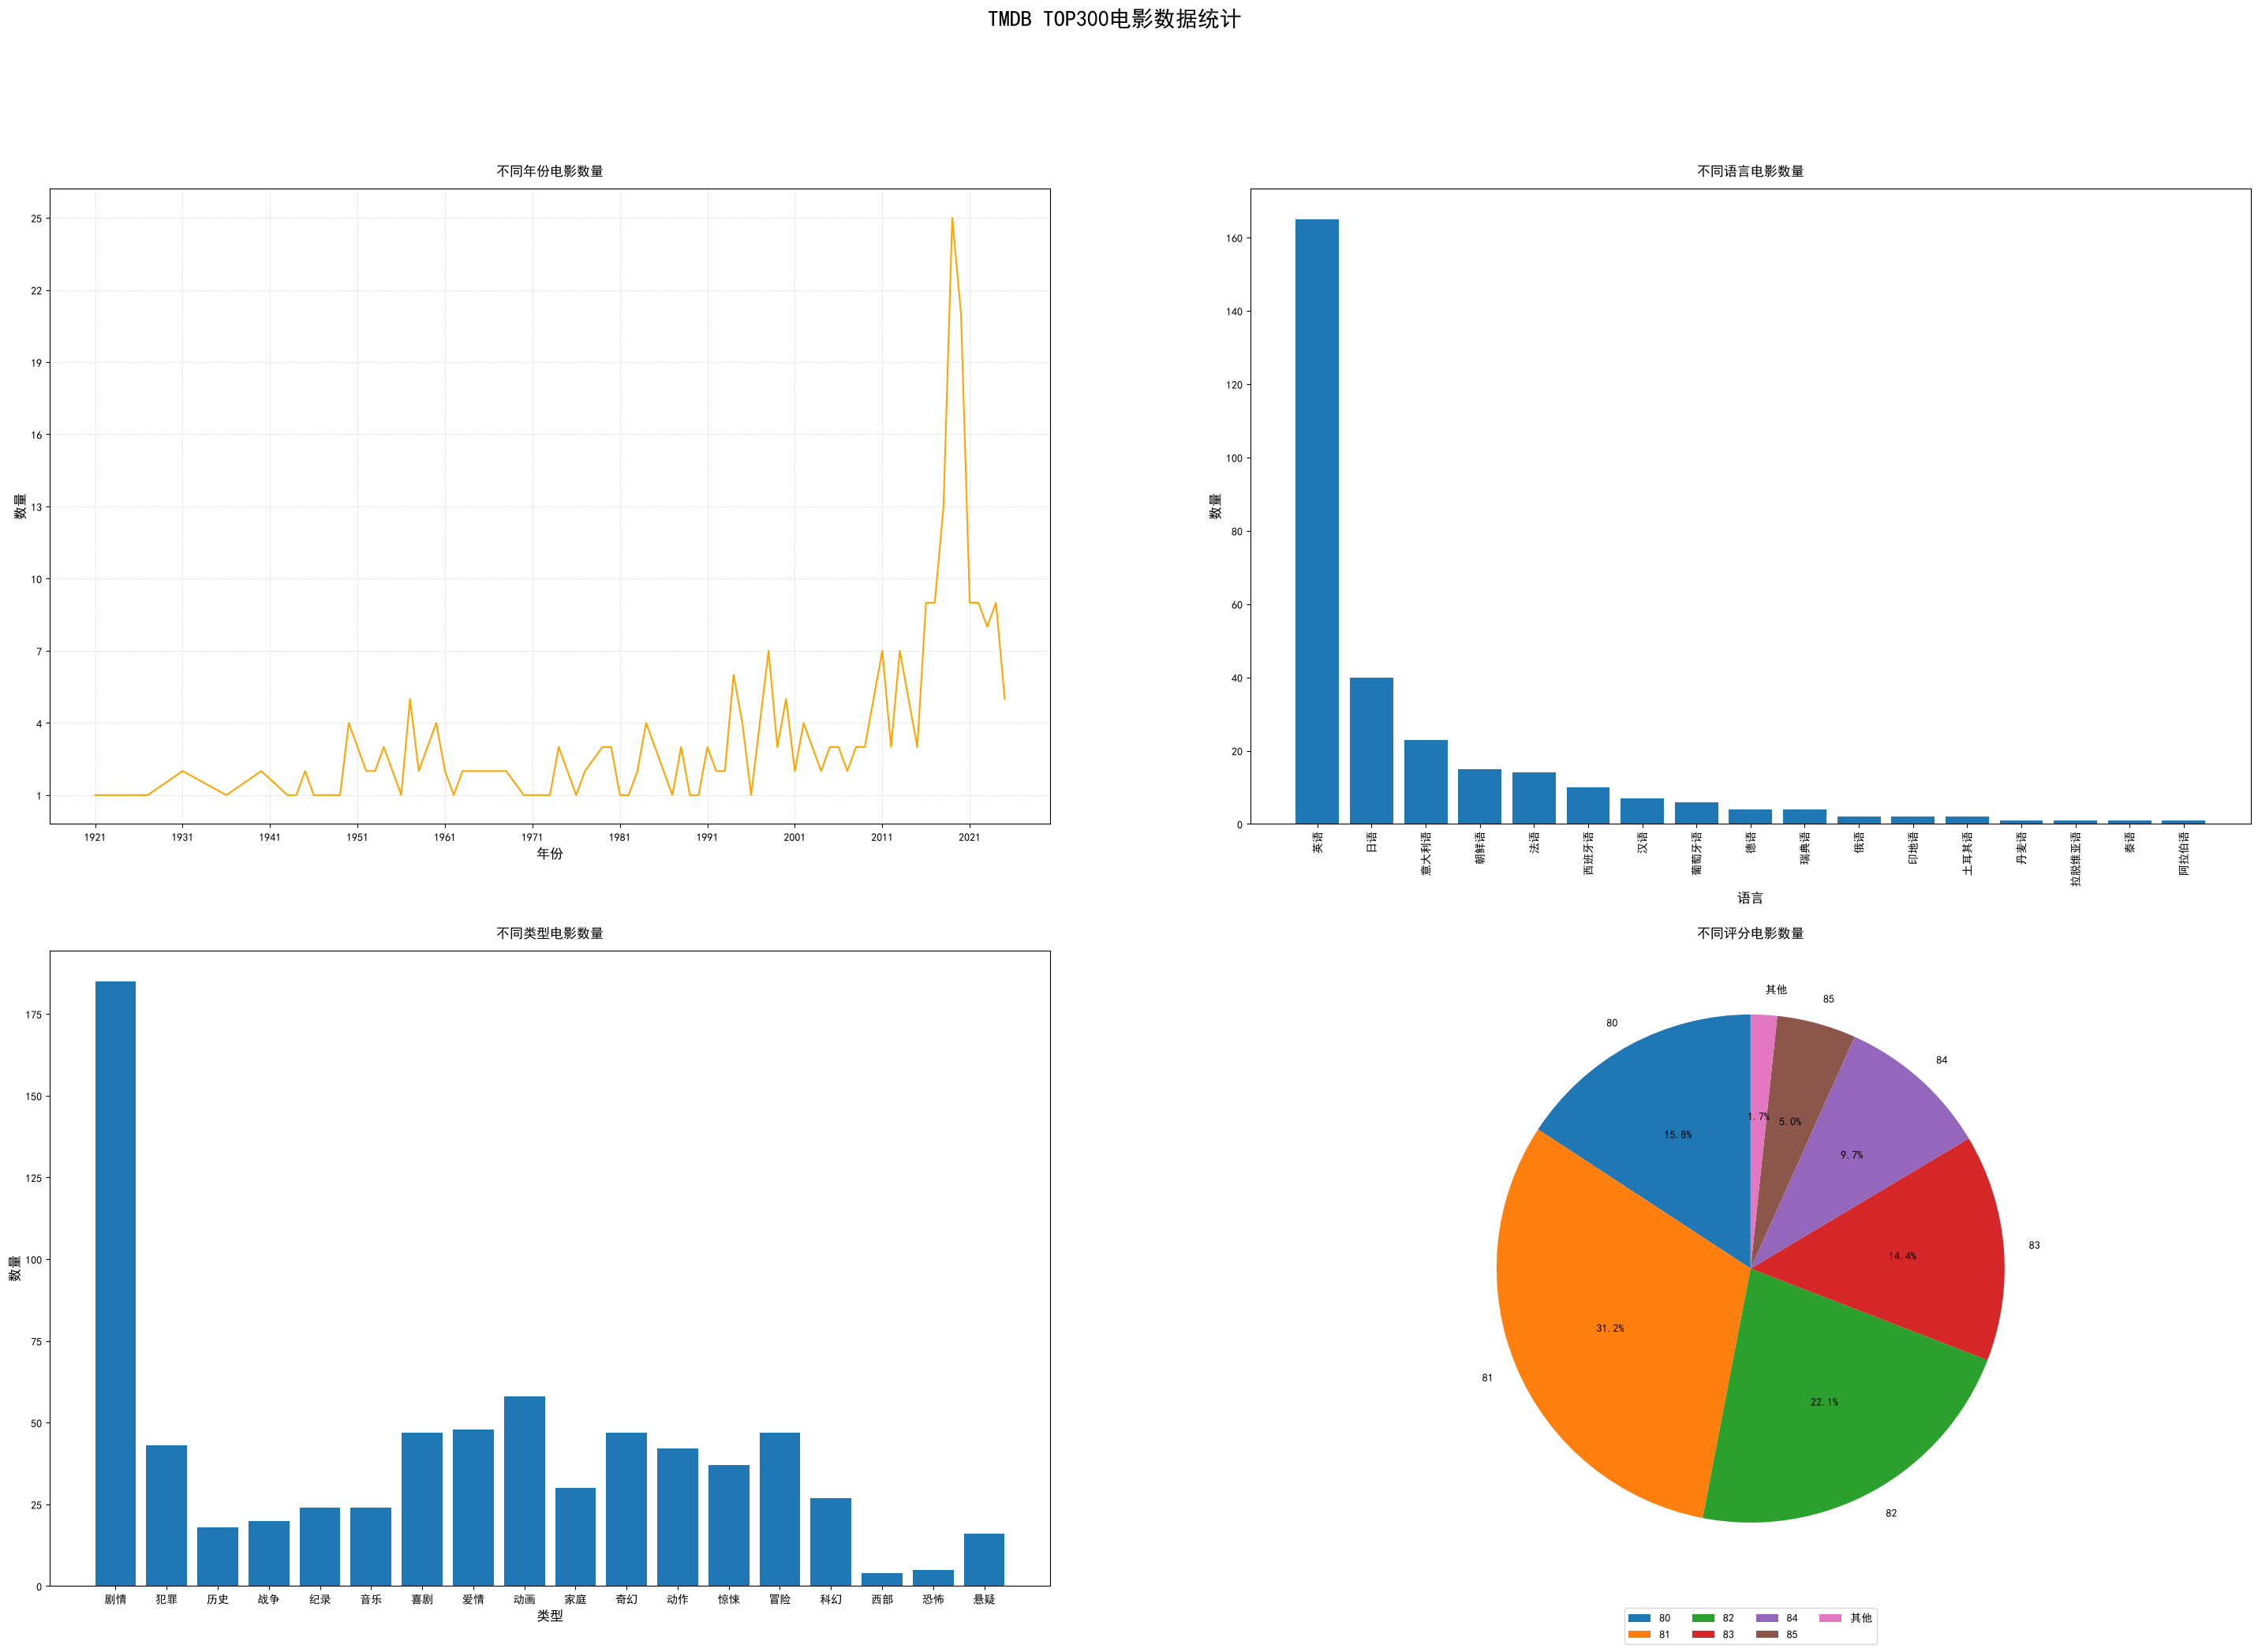

In [48]:
import matplotlib.pyplot as plt
import pandas as pd

# - 配置运行时参数（字体、中文显示）
plt.rcParams['font.sans-serif'] = ['SimHei']  # 支持中文显示

df = pd.read_csv("./resources/movies.csv", encoding="utf-8")

# 对年份进行数据清理
df = df.dropna(subset=['年份'])
df['年份'] = df['年份'].astype(int)

# 对重复数据进行清洗
df.drop_duplicates(subset=['电影名'])

# 创建子图
figure, axes = plt.subplots(nrows=2, ncols=2, figsize=(36,23), dpi = 100)

# 设置画布的标题
figure.suptitle("TMDB TOP300电影数据统计", fontsize=20)

ax1 = axes[0, 0]
ax2 = axes[0, 1]
ax3 = axes[1, 0]
ax4 = axes[1, 1]

# 第一个子图

#获取x轴的信息
date_mess = df.groupby('年份')['年份'].count()
ax1_x = date_mess.index
ax1_y = date_mess.values

# 绘制第一个子图
ax1.plot(ax1_x,ax1_y, color='#FFA500')

ax1.set_title("不同年份电影数量",fontsize = 12, pad = 12)

ax1.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

# 设置x轴的标签
ax1.set_xlabel("年份",fontsize = 12)
# 设置x轴的刻度
ax1.set_xticks(range(min(ax1_x), max(ax1_x)+1, 10))

# 设置y轴的标签
ax1.set_ylabel("数量",fontsize = 12)
# 设置y轴的刻度
ax1.set_yticks(range(min(ax1_y), max(ax1_y)+1, 3))
                
                
                
                
# 第二个视图

# 获取数据
mess = df.groupby('语言')['语言'].count()
# 获取语言信息
language_mess = mess.sort_values(ascending=False)

ax2_x = language_mess.index
ax2_y = language_mess.values

# 绘制第二个子图
ax2.bar(ax2_x,ax2_y)

ax2.set_title("不同语言电影数量",fontsize = 12, pad = 12)

ax2.set_xlabel("语言",fontsize = 12)
ax2.set_xticks(ax2_x,labels= ax2_x, rotation=90)

ax2.set_ylabel("数量",fontsize = 12)








# 第三个子图

content_mess = df['类型'].values

content_list = []

for content in content_mess:
    if "," in content:
        content_list.extend(content.split(","))     # 分割并添加到列表中
    else:
        content_list.append(content)
        
        
content_dict = {}

# 统计类型数量
for content in content_list:
    if content not in content_dict:
        content_dict[content] = 1
    else:
        content_dict[content] += 1

ax3_x = content_dict.keys()
ax3_y = content_dict.values()

ax3.bar(ax3_x,ax3_y)

ax3.set_title("不同类型电影数量",fontsize = 12, pad = 12)

ax3.set_xlabel("类型",fontsize = 12)
ax3.set_ylabel("数量",fontsize = 12)










# 第四个子图

score_mess = df.groupby('评分')['评分'].count()

sum = score_mess.values.sum()

score_dict = {}

for k,v in score_mess.items():
    if v/sum < 0.05:
        score_dict['其他'] = score_dict.get('其他', 0) + v 
    else:
        score_dict[k] = v

score_series = pd.Series(score_dict)

score = score_series.index
rating = score_series.values

ax4.pie(rating, labels=score, autopct='%1.1f%%', startangle=90)

ax4.set_title("不同评分电影数量",fontsize = 12, pad = 12)

ax4.legend(loc='lower center', fontsize=10, ncol=4, bbox_to_anchor=(0.5, -0.1))


plt.show()



